In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [24]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
dermatology = fetch_ucirepo(id=33) 
  
# data (as pandas dataframes) 
X = dermatology.data.features 
y = dermatology.data.targets 
  
# metadata 
print(dermatology.metadata) 
  
# variable information 
print(dermatology.variables) 


{'uci_id': 33, 'name': 'Dermatology', 'repository_url': 'https://archive.ics.uci.edu/dataset/33/dermatology', 'data_url': 'https://archive.ics.uci.edu/static/public/33/data.csv', 'abstract': 'Aim for this dataset is to determine the type of Eryhemato-Squamous Disease.', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 366, 'num_features': 34, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age'], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1998, 'last_updated': 'Wed Feb 14 2024', 'dataset_doi': '10.24432/C5FK5P', 'creators': ['Nilsel Ilter', 'H. Guvenir'], 'intro_paper': {'ID': 387, 'type': 'NATIVE', 'title': 'Learning differential diagnosis of erythemato-squamous diseases using voting feature intervals', 'authors': 'H. Altay Güvenir, G. Demiröz, N. Ilter', 'venue': 'Artif. Intell. Medicine', 'year': 1998, 'journal': No

In [25]:
X.head()

,erythema,scaling,definite-borders,itching,koebner phenomenon,polygonal papules,follicular papules,oral-mucosal involvement,knee elbow involvement,scalp involvement,...,focal hypergranulosis,disappearance of the granular layer,vacuolisation and damage of the basal layer,spongiosis,saw-tooth appearance of retes,follicular horn plug,perifollicular parakeratosis,inflammatory monoluclear infiltrate,band-like infiltrate,age
0,2,2,0,3,0,0,0,0,1,0,...,0,0,0,3,0,0,0,1,0,55.0
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,0,1,0,8.0
2,2,1,2,3,1,3,0,3,0,0,...,2,0,2,3,2,0,0,2,3,26.0
3,2,2,2,0,0,0,0,0,3,2,...,0,3,0,0,0,0,0,3,0,40.0
4,2,3,2,2,2,2,0,2,0,0,...,2,2,3,2,3,0,0,2,3,45.0


In [26]:
X.shape

(366, 34)

In [27]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 34 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   erythema                                     366 non-null    int64  
 1   scaling                                      366 non-null    int64  
 2   definite-borders                             366 non-null    int64  
 3   itching                                      366 non-null    int64  
 4   koebner phenomenon                           366 non-null    int64  
 5   polygonal papules                            366 non-null    int64  
 6   follicular papules                           366 non-null    int64  
 7   oral-mucosal involvement                     366 non-null    int64  
 8   knee elbow involvement                       366 non-null    int64  
 9   scalp involvement                            366 non-null    int64  
 10  family histor

In [28]:
df = pd.concat([X, y], axis=1)
df = df.dropna()
df = df.reset_index(drop=True)

# Split back
X = df.drop(columns=['class'])
y = df[['class']]

In [29]:
y.head()

,class
0,2
1,1
2,3
3,1
4,3


In [30]:
num_classes = y['class'].nunique()
num_classes

6

In [31]:
y.value_counts()

class
1        111
3         71
2         60
5         48
4         48
6         20
Name: count, dtype: int64

In [32]:
# map the target variable to their corresponding class names
class_mapping = {1: 'psoriasis', 2: 'seborrheic dermatitis', 3: 'lichen planus', 4: 'pityriasis rosea', 5: 'chronic dermatitis', 6: 'pityriasis rubra pilaris'}
y['class_name'] = y['class'].map(class_mapping)
y.head()

,class,class_name
0,2,seborrheic dermatitis
1,1,psoriasis
2,3,lichen planus
3,1,psoriasis
4,3,lichen planus


=== CLASS DISTRIBUTION ===
class_name
psoriasis                   111
lichen planus                71
seborrheic dermatitis        60
chronic dermatitis           48
pityriasis rosea             48
pityriasis rubra pilaris     20
Name: count, dtype: int64

Imbalance ratio (largest:smallest): 111:20


([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'psoriasis'),
  Text(1, 0, 'lichen planus'),
  Text(2, 0, 'seborrheic dermatitis'),
  Text(3, 0, 'chronic dermatitis'),
  Text(4, 0, 'pityriasis rosea'),
  Text(5, 0, 'pityriasis rubra pilaris')])

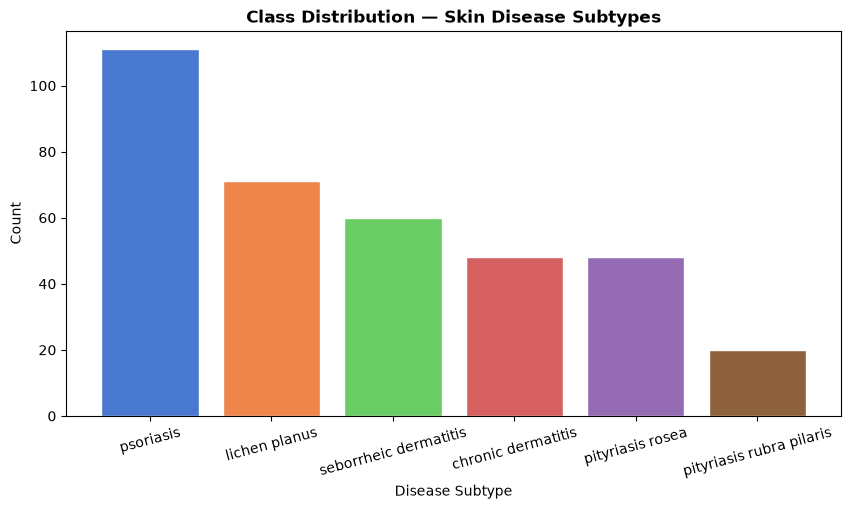

In [33]:
counts = y['class_name'].value_counts()
print("=== CLASS DISTRIBUTION ===")
print(counts)
print(f"\nImbalance ratio (largest:smallest): {counts.max()}:{counts.min()}")

# Plot
plt.figure(figsize=(10, 5))
colors = sns.color_palette("muted", 6)
bars = plt.bar(counts.index, counts.values, color=colors, edgecolor='white')
plt.title("Class Distribution — Skin Disease Subtypes", fontweight="bold")
plt.xlabel("Disease Subtype")
plt.ylabel("Count")
plt.xticks(rotation=15)

In [34]:
y=y.drop(columns=['class_name'])
y

,class
0,2
1,1
2,3
3,1
4,3
...,...
353,4
354,4
355,3
356,3


In [35]:
#Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [36]:
#split the dataset into training, validation and testing sets
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [37]:
#convert the data to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values - 1, dtype=torch.long)
y_train_tensor = y_train_tensor.squeeze() # Remove any extra dimensions
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values - 1, dtype=torch.long)
y_val_tensor = y_val_tensor.squeeze()  # Remove any extra dimensions
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values - 1, dtype=torch.long)
y_test_tensor = y_test_tensor.squeeze()  # Remove any extra dimensions

# Confirm shapes
print(f"✅ Train set: {X_train_tensor.shape}")
print(f"✅ Validation set: {X_val_tensor.shape}")
print(f"✅ Test set: {X_test_tensor.shape}")
print(f"✅ y set: {y_train_tensor.shape}")
print(f"✅ Number of Classes: {y['class'].nunique()}")
print(f"✅ Class Names: {class_mapping.values()}")

✅ Train set: torch.Size([250, 34])
✅ Validation set: torch.Size([54, 34])
✅ Test set: torch.Size([54, 34])
✅ y set: torch.Size([250])
✅ Number of Classes: 6
✅ Class Names: dict_values(['psoriasis', 'seborrheic dermatitis', 'lichen planus', 'pityriasis rosea', 'chronic dermatitis', 'pityriasis rubra pilaris'])


In [38]:
print("X dtype:", X_train_tensor.dtype)   # must be torch.float32
print("y dtype:", y_train_tensor.dtype)   # must be torch.int64
print("y unique values:", torch.unique(y_train_tensor))  # must be 0,1,2,3,4,5
print("X contains nan:", torch.isnan(X_train_tensor).any())
print("X contains inf:", torch.isinf(X_train_tensor).any())

X dtype: torch.float32
y dtype: torch.int64
y unique values: tensor([0, 1, 2, 3, 4, 5])
X contains nan: tensor(False)
X contains inf: tensor(False)


In [45]:
class DermMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout_rate=0.5):
        super(DermMLP, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p = dropout_rate),  # Add dropout layer
            nn.Linear(hidden_dim, output_dim)
        )
    def forward(self, x):
       return self.model(x)

In [40]:
num_classes = len(class_mapping)
unique_classes, counts = torch.unique(y_train_tensor, return_counts=True)
for class_idx, count in zip(unique_classes, counts):
    print("Count of samples in class {}: {}".format(class_idx.item(), count.item()))

Count of samples in class 0: 77
Count of samples in class 1: 42
Count of samples in class 2: 50
Count of samples in class 3: 33
Count of samples in class 4: 34
Count of samples in class 5: 14


In [46]:

model = DermMLP(X_train_tensor.shape[1], 64, num_classes)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

In [47]:
num_epochs = 200
train_losses = []
train_acc = []
val_losses = []

for epoch in range(num_epochs):
    # Training
    model.train()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    #Validation phase
    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val_tensor)
        val_loss = criterion(val_outputs, y_val_tensor)
        val_losses.append(val_loss.item())

    #compute accuracy
    preds = torch.argmax(outputs, dim=1)
    acc = (preds == y_train_tensor).float().mean().item()
    train_acc.append(acc)

    
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:>2} | Train Loss: {loss.item():.4f} | Val Loss = {val_loss.item():.4f} | Accuracy: {acc*100:.2f}%")



Epoch 10 | Train Loss: 1.5366 | Val Loss = 1.4777 | Accuracy: 51.60%
Epoch 20 | Train Loss: 1.2655 | Val Loss = 1.2080 | Accuracy: 73.20%
Epoch 30 | Train Loss: 1.0122 | Val Loss = 0.9601 | Accuracy: 82.40%
Epoch 40 | Train Loss: 0.8056 | Val Loss = 0.7481 | Accuracy: 86.40%
Epoch 50 | Train Loss: 0.6196 | Val Loss = 0.5826 | Accuracy: 90.80%
Epoch 60 | Train Loss: 0.5023 | Val Loss = 0.4591 | Accuracy: 92.80%
Epoch 70 | Train Loss: 0.4010 | Val Loss = 0.3680 | Accuracy: 92.80%
Epoch 80 | Train Loss: 0.3355 | Val Loss = 0.3028 | Accuracy: 93.60%
Epoch 90 | Train Loss: 0.2965 | Val Loss = 0.2573 | Accuracy: 94.00%
Epoch 100 | Train Loss: 0.2427 | Val Loss = 0.2234 | Accuracy: 96.40%
Epoch 110 | Train Loss: 0.2243 | Val Loss = 0.1980 | Accuracy: 96.00%
Epoch 120 | Train Loss: 0.1856 | Val Loss = 0.1793 | Accuracy: 96.80%
Epoch 130 | Train Loss: 0.1718 | Val Loss = 0.1647 | Accuracy: 96.80%
Epoch 140 | Train Loss: 0.1652 | Val Loss = 0.1529 | Accuracy: 97.60%
Epoch 150 | Train Loss: 0.152

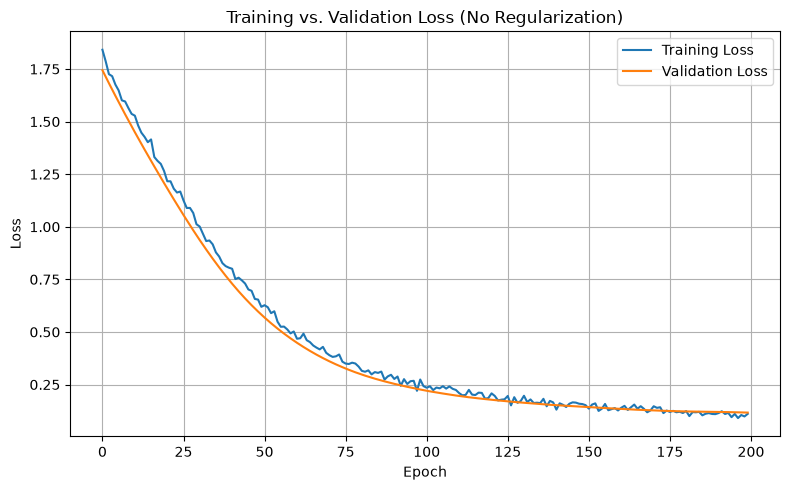

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs. Validation Loss (No Regularization)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [49]:
def evaluate_model(model, X_test_tensor, y_test_tensor):
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_tensor)
        test_loss = criterion(test_outputs, y_test_tensor)
        preds = torch.argmax(test_outputs, dim=1)
        acc = (preds == y_test_tensor).float().mean().item()
        
    print(f"Test Loss: {test_loss.item():.4f} | Test Accuracy: {acc*100:.2f}%")

In [50]:
evaluate_model(model, X_test_tensor, y_test_tensor)

Test Loss: 0.0761 | Test Accuracy: 96.30%


In [43]:
# Evaluate the model on the test set
test_losses = []
num_epochs = 200
for epoch in range(num_epochs):
   
model.eval() 
with torch.no_grad():
    test_outputs = model(X_test_tensor)
    test_loss = criterion(test_outputs, y_test_tensor)
    test_losses.append(test_loss.item())
    print(f"Test Loss: {test_loss.item():.4f}")

IndentationError: expected an indented block after 'for' statement on line 4 (2652062199.py, line 6)